## AJQ Job Satisfaction — Neural Network Feature Experiments
Target: Q4 rating 8–10 = 1 (highly satisfied); 0–7 = 0 (not highly satisfied). Class 0 does not necessarily mean dissatisfied.

Evaluation protocol: fixed stratified 67% development / 33% test split (random_state=1234); 80% of development for fitting, 20% for validation. Select features, optimizer, architecture, and LR regularization using validation only. Refit selected models on the entire 67% development sample before one final test comparison.

## 1. Import packages and set reproducible seeds
The CNN lab uses tensorflow.keras as keras, Sequential, compile, fit, and evaluate. We preserve those concepts here.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, roc_auc_score,
                             f1_score, precision_score, recall_score, log_loss,
                             confusion_matrix, classification_report)
try:
    import tensorflow as tf
    from tensorflow import keras
    BACKEND = f"TensorFlow {tf.__version__}"
except ModuleNotFoundError:
    os.environ["KERAS_BACKEND"] = "torch"
    import keras
    BACKEND = f"Keras {keras.__version__} / {keras.backend.backend()} backend"
    # Limit CPU threading in PyTorch environments for faster small tabular models.
    try:
        import torch
        torch.set_num_threads(2)
    except ImportError:
        pass

SEED = 1234
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)
DATA_DIR = Path("../data")
if not (DATA_DIR / "JFF_formatted_public_release_labels.csv").exists():
    DATA_DIR = Path("/mnt/data")
OUTPUT_DIR = Path("ajq_nn_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
print("Backend:", BACKEND)
print("Data:", DATA_DIR.resolve())

Backend: TensorFlow 2.21.0
Data: /Users/nadiaalexander/Desktop/BTT/Swytch-2C-predicting-job-satisfaction-from-person-job-fit/data


## 2. Load and align the two datasets

In [2]:
ajq = pd.read_csv(DATA_DIR / "JFF_formatted_public_release_labels.csv",
                  encoding="latin1", low_memory=False)
ajq["Q4_Numeric"] = pd.to_numeric(
    ajq["Q4"].astype(str).str.extract(r"^(\d+)")[0], errors="coerce"
)
ajq = ajq.loc[ajq["Q4_Numeric"].between(0, 10)].copy().reset_index(drop=True)
ajq["Highly_Satisfied"] = (ajq["Q4_Numeric"] >= 8).astype(int)
y = ajq["Highly_Satisfied"].to_numpy(dtype=np.int32)
print(f"Valid respondents: {len(ajq):,}")
print("Class distribution (0 = not highly satisfied; 1 = highly satisfied):")
print(ajq["Highly_Satisfied"].value_counts(normalize=True).round(3))

Valid respondents: 18,381
Class distribution (0 = not highly satisfied; 1 = highly satisfied):
Highly_Satisfied
0    0.584
1    0.416
Name: proportion, dtype: float64


## 3. Select the same feature groups as logistic regression

In [3]:
baseline_features = [
    "Q20", "Q40", "Q14", "Q65", "Q9", "Q8", "Q17",
    "MARITAL_STATUS", "EDUCATION", "Q51", "REGION"
]
job_quality_features = [
    "Q33A", "Q33B", "Q33C", "Q33D", "Q33E",
    "Q33F", "Q33G", "Q33H", "Q33I", "Q33J", "Q55"
]
scheduling_features = ["Q23", "Q24", "Q25A", "Q25B", "Q25C", "Q25D", "Q27"]
growth_features = ["Q34", "Q35A", "Q35B", "Q35C", "Q35D"]
security_features = ["Q36", "Q41"]

expanded_features = list(dict.fromkeys(baseline_features + job_quality_features))
all_features = list(dict.fromkeys(expanded_features + scheduling_features + growth_features + security_features))

feature_groups = {
    "Baseline": baseline_features,
    "Baseline + Job Quality": expanded_features,
    "+ Scheduling": expanded_features + scheduling_features,
    "+ Growth": expanded_features + growth_features,
    "+ Security": expanded_features + security_features,
    "+ All New Features": all_features
}

feature_groups = {name: list(dict.fromkeys(cols)) for name, cols in feature_groups.items()}

for name, cols in feature_groups.items():
    missing = sorted(set(cols) - set(ajq.columns))
    if missing:
        raise KeyError(f"{name}: missing columns {missing}")
    
    print(f"{name:24s} {len(cols):2d} original features")

Baseline                 11 original features
Baseline + Job Quality   22 original features
+ Scheduling             29 original features
+ Growth                 27 original features
+ Security               24 original features
+ All New Features       36 original features


## 4. Make a shared train / validation / test split
- Test (33%): held out until final evaluation
- Validation (~13.4%): taken from the 67% training portion
- Actual training (~53.6%): used to fit encoders/scalers and network weights

In [4]:
indices = np.arange(len(y))
trainval_idx, test_idx = train_test_split(indices, test_size=0.33, random_state=SEED, stratify=y)

train_idx, val_idx = train_test_split(trainval_idx, test_size=0.20, random_state=SEED, stratify=y[trainval_idx])

print("Train / validation / test:", len(train_idx), len(val_idx), len(test_idx))
print("Positive-class rates:",
      *[f"{y[idx].mean():.3f}" for idx in (train_idx, val_idx, test_idx)])

Train / validation / test: 9852 2463 6066
Positive-class rates: 0.416 0.416 0.416


## 5. Clean and encode survey features using training data only
- Q20, Q17, and Q51 are treated as quantitative
- The remaining selected AJQ variables are treated as categorical.
- Missing numerical values are imputed with training medians, categorical values with Missing.
- One-hot encoding uses handle_unknown="ignore" so unseen categories in validation/test cannot break predictions.
- Standardize numeric fields using training statistics. No information from validation/test is used to fit transformations.

In [5]:
numeric_candidates = ["Q20", "Q17", "Q51"]

def prepare_raw_features(source, features):
    X = source[features].copy()
    X = X.replace(r"^\s*$", np.nan, regex=True)
    X = X.replace(["No response", "Not sure", "Not applicable"], np.nan)
    
    if "Q20" in features:
        X["Q20"] = pd.to_numeric(X["Q20"], errors="coerce")
    if "Q17" in features:
        X["Q17"] = pd.to_numeric(X["Q17"].astype(str).str.extract(r"^(\d+)")[0], errors="coerce")
    if "Q51" in features:
        X["Q51"] = pd.to_numeric(X["Q51"], errors="coerce")
    return X

def preprocess_for_split(features, fit_idx, other_idx):
    """Fit encoders on fit_idx only, then transform both sets."""
    X = prepare_raw_features(ajq, features)
    num_cols = [c for c in numeric_candidates if c in features]
    cat_cols = [c for c in features if c not in num_cols]
    
    for col in cat_cols:
        X[col] = X[col].astype("object").where(X[col].notna(), "Missing").astype(str)

    preprocessor = ColumnTransformer([
        ("numeric", Pipeline([
            ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("scale", StandardScaler())
        ]), num_cols),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)
    ], remainder="drop", sparse_threshold=0.0)

    X_fit = preprocessor.fit_transform(X.iloc[fit_idx]).astype(np.float32)
    X_other = preprocessor.transform(X.iloc[other_idx]).astype(np.float32)
    
    return X_fit, X_other, preprocessor

## 6. Construct and compile the neural network
Use the keras.Sequential() network with 64 → 32 → 16 ReLU hidden units and one sigmoid output, compiled with SGD (learning rate 0.1) and binary cross-entropy.

In [6]:
def build_nn(n_features, architecture=(64, 32, 16), optimizer="sgd", dropout=0.0):
    layers = [keras.layers.Input(shape=(n_features,))]
    
    for width in architecture:
        layers.append(keras.layers.Dense(width, activation="relu"))
        if dropout:
            layers.append(keras.layers.Dropout(dropout))
    
    layers.append(keras.layers.Dense(1, activation="sigmoid"))
    model = keras.Sequential(layers)
    opt = (keras.optimizers.SGD(learning_rate=0.1) if optimizer == "sgd"
           else keras.optimizers.Adam(learning_rate=0.001))
    
    model.compile(optimizer=opt, loss="binary_crossentropy", metrics=["accuracy"])
    return model

def evaluate_binary(y_true, probabilities, threshold=0.50):
    predicted = (np.asarray(probabilities).ravel() >= threshold).astype(int)
    probabilities = np.asarray(probabilities).ravel()
    
    return {
        "Accuracy": accuracy_score(y_true, predicted),
        "Balanced Accuracy": balanced_accuracy_score(y_true, predicted),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "F1": f1_score(y_true, predicted, zero_division=0),
        "Precision": precision_score(y_true, predicted, zero_division=0),
        "Recall": recall_score(y_true, predicted, zero_division=0),
        "Log Loss": log_loss(y_true, probabilities),
        "Predictions": predicted,
        "Probabilities": probabilities
    }

def train_nn_on_validation(X_fit, X_val, architecture=(64, 32, 16), optimizer="sgd", dropout=0.0):
    keras.utils.set_random_seed(SEED)
    model = build_nn(X_fit.shape[1], architecture, optimizer, dropout)
    
    history = model.fit(
        X_fit, y[train_idx], validation_data=(X_val, y[val_idx]),
        epochs=100, batch_size=128, verbose=0,
        callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)]
    )
    
    probs = model.predict(X_val, verbose=0).ravel()
    
    metrics = evaluate_binary(y[val_idx], probs)
    metrics["Best Epoch"] = int(np.argmin(history.history["val_loss"]) + 1)
    metrics["Epochs Run"] = len(history.history["loss"])
    
    return metrics, history.history

## 7. Train and evaluate using Keras built-in fit and predict
For each feature group, we create a new network and call fit once. This uses the same train, validation, and test respondents for all five models. We use 100 epochs with Keras's built-in EarlyStopping to restore the best validation-loss weights.

In [7]:
feature_rows = []
feature_histories = {}

for name, features in feature_groups.items():
    X_fit, X_val, _ = preprocess_for_split(features, train_idx, val_idx)
    
    for optimizer in ("sgd", "adam"):
        metrics, history = train_nn_on_validation(X_fit, X_val, optimizer=optimizer)
        feature_histories[(name, optimizer)] = history
        feature_rows.append({
            "Feature Group": name,
            "Optimizer": optimizer.upper(),
            "Encoded Features": X_fit.shape[1],
            **{k: metrics[k] for k in ("Accuracy", "ROC-AUC", "F1", "Log Loss", "Best Epoch")}
        })
        
        print(f"{name:24s} {optimizer.upper():4s} | "
              f"val accuracy {metrics['Accuracy']:.4f} | "
              f"AUC {metrics['ROC-AUC']:.4f} | "
              f"F1 {metrics['F1']:.4f} | epoch {metrics['Best Epoch']}")

feature_comparison = pd.DataFrame(feature_rows)
display(feature_comparison.sort_values(["Accuracy", "ROC-AUC"], ascending=False).round(4))
feature_comparison.to_csv(OUTPUT_DIR / "nn_feature_group_validation.csv", index=False)

best_feature_row = feature_comparison.sort_values(["Accuracy", "ROC-AUC"], ascending=False).iloc[0]

best_feature_group = best_feature_row["Feature Group"]
best_optimizer = best_feature_row["Optimizer"].lower()
print("Best validation feature group:", best_feature_group, "| optimizer:", best_optimizer.upper())

Baseline                 SGD  | val accuracy 0.6090 | AUC 0.6345 | F1 0.4519 | epoch 7
Baseline                 ADAM | val accuracy 0.6135 | AUC 0.6355 | F1 0.4299 | epoch 2
Baseline + Job Quality   SGD  | val accuracy 0.7564 | AUC 0.8285 | F1 0.7209 | epoch 6
Baseline + Job Quality   ADAM | val accuracy 0.7507 | AUC 0.8298 | F1 0.7017 | epoch 3
+ Scheduling             SGD  | val accuracy 0.7617 | AUC 0.8314 | F1 0.7304 | epoch 6
+ Scheduling             ADAM | val accuracy 0.7653 | AUC 0.8340 | F1 0.7263 | epoch 3
+ Growth                 SGD  | val accuracy 0.7519 | AUC 0.8291 | F1 0.7186 | epoch 7
+ Growth                 ADAM | val accuracy 0.7596 | AUC 0.8316 | F1 0.7148 | epoch 2
+ Security               SGD  | val accuracy 0.7605 | AUC 0.8331 | F1 0.7279 | epoch 6
+ Security               ADAM | val accuracy 0.7605 | AUC 0.8331 | F1 0.7204 | epoch 3
+ All New Features       SGD  | val accuracy 0.7580 | AUC 0.8365 | F1 0.7274 | epoch 7
+ All New Features       ADAM | val accurac

,Feature Group,Optimizer,Encoded Features,Accuracy,ROC-AUC,F1,Log Loss,Best Epoch
5,+ Scheduling,ADAM,162,0.7653,0.8340,0.7263,0.4963,3
11,+ All New Features,ADAM,189,0.7629,0.8383,0.7253,0.4910,3
4,+ Scheduling,SGD,162,0.7617,0.8314,0.7304,0.5029,6
9,+ Security,ADAM,137,0.7605,0.8331,0.7204,0.4973,3
8,+ Security,SGD,137,0.7605,0.8331,0.7279,0.5010,6
7,+ Growth,ADAM,140,0.7596,0.8316,0.7148,0.4976,2
10,+ All New Features,SGD,189,0.7580,0.8365,0.7274,0.4975,7
2,Baseline + Job Quality,SGD,125,0.7564,0.8285,0.7209,0.5049,6
6,+ Growth,SGD,140,0.7519,0.8291,0.7186,0.5055,7
3,Baseline + Job Quality,ADAM,125,0.7507,0.8298,0.7017,0.5007,3


Best validation feature group: + Scheduling | optimizer: ADAM


## 8. Small architecture experiment on the best feature group
Compare the original 64–32–16 network against smaller/larger networks and a dropout version. 

In [10]:
X_fit_best, X_val_best, _ = preprocess_for_split(feature_groups[best_feature_group], train_idx, val_idx)

architecture_options = [("Original 64-32-16", (64, 32, 16), 0.0), ("Small 32-16", (32, 16), 0.0),
    ("Large 128-64-32", (128, 64, 32), 0.0), ("Original + Dropout 0.2", (64, 32, 16), 0.2)]

architecture_rows = []
architecture_histories = {}

for label, architecture, dropout in architecture_options:
    metrics, history = train_nn_on_validation(X_fit_best, X_val_best, architecture, best_optimizer, dropout)
    
    architecture_histories[label] = history
    architecture_rows.append({ "Architecture": label, "Layers": architecture, "Dropout": dropout,
        **{k: metrics[k] for k in ("Accuracy", "ROC-AUC", "F1", "Log Loss", "Best Epoch")}
    })

architecture_comparison = pd.DataFrame(architecture_rows)
display(architecture_comparison.sort_values(["Accuracy", "ROC-AUC"], ascending=False).round(4))
best_arch_row = architecture_comparison.sort_values(["Accuracy", "ROC-AUC"], ascending=False).iloc[0]

selected_architecture = tuple(best_arch_row["Layers"])
selected_dropout = float(best_arch_row["Dropout"])
selected_epochs = int(best_arch_row["Best Epoch"])

print("Selected NN:", best_feature_group, best_optimizer, selected_architecture, "dropout", selected_dropout,
      "epochs", selected_epochs)

,Architecture,Layers,Dropout,Accuracy,ROC-AUC,F1,Log Loss,Best Epoch
3,Original + Dropout 0.2,"(64, 32, 16)",0.2,0.7674,0.8376,0.7247,0.4935,6
0,Original 64-32-16,"(64, 32, 16)",0.0,0.7653,0.8340,0.7263,0.4963,3
1,Small 32-16,"(32, 16)",0.0,0.7649,0.8385,0.7244,0.4901,5
2,Large 128-64-32,"(128, 64, 32)",0.0,0.7592,0.8361,0.7230,0.4951,3


Selected NN: + Scheduling adam (64, 32, 16) dropout 0.2 epochs 6


## 10. Refit selected NN and LR, then evaluate on the same test set
The neural network trains for the validation-selected number of epochs on all 67% development respondents

In [11]:
lr_rows = []
for name, features in feature_groups.items():
    X_fit, X_val, _ = preprocess_for_split(features, train_idx, val_idx)
    for c_value in (0.001, 0.01, 0.1, 1.0):
        lr = LogisticRegression(C=c_value, max_iter=2000, random_state=42)
        lr.fit(X_fit, y[train_idx])
        metrics = evaluate_binary(y[val_idx], lr.predict_proba(X_val)[:, 1])
        lr_rows.append({
            "Feature Group": name, "C": c_value,
            **{k: metrics[k] for k in ("Accuracy", "ROC-AUC", "F1", "Log Loss")}
        })
lr_comparison = pd.DataFrame(lr_rows)
display(lr_comparison.sort_values(["Accuracy", "ROC-AUC"], ascending=False).head(12).round(4))
lr_comparison.to_csv(OUTPUT_DIR / "lr_validation_benchmark.csv", index=False)
selected_lr_row = lr_comparison.sort_values(
    ["Accuracy", "ROC-AUC"], ascending=False
).iloc[0]
selected_lr_features = selected_lr_row["Feature Group"]
selected_c = float(selected_lr_row["C"])
print("Selected LR:", selected_lr_features, "C =", selected_c)

,Feature Group,C,Accuracy,ROC-AUC,F1,Log Loss
17,+ Security,0.01,0.7751,0.8392,0.7290,0.4895
9,+ Scheduling,0.01,0.7743,0.8407,0.7234,0.4903
21,+ All New Features,0.01,0.7739,0.8432,0.7260,0.4838
5,Baseline + Job Quality,0.01,0.7734,0.8359,0.7221,0.4960
22,+ All New Features,0.10,0.7714,0.8431,0.7274,0.4832
10,+ Scheduling,0.10,0.7686,0.8399,0.7228,0.4882
23,+ All New Features,1.00,0.7678,0.8415,0.7234,0.4859
18,+ Security,0.10,0.7678,0.8385,0.7245,0.4889
6,Baseline + Job Quality,0.10,0.7670,0.8350,0.7192,0.4944
13,+ Growth,0.01,0.7661,0.8363,0.7140,0.4938


Selected LR: + Security C = 0.01


In [12]:
# Final neural network: feature group, optimizer, architecture and epoch count
# were all selected without using test labels.
X_nn_dev, X_nn_test, nn_preprocessor = preprocess_for_split(feature_groups[best_feature_group], trainval_idx, test_idx)

keras.utils.set_random_seed(SEED)
final_nn = build_nn(X_nn_dev.shape[1], selected_architecture, best_optimizer, selected_dropout)

final_nn_history = final_nn.fit(X_nn_dev, y[trainval_idx], epochs=selected_epochs, batch_size=128, verbose=0)

nn_test_probabilities = final_nn.predict(X_nn_test, verbose=0).ravel()
nn_test_metrics = evaluate_binary(y[test_idx], nn_test_probabilities)

# Final logistic regression, using its separately selected feature group and C.
X_lr_dev, X_lr_test, lr_preprocessor = preprocess_for_split(
    feature_groups[selected_lr_features], trainval_idx, test_idx
)

final_lr = LogisticRegression(C=selected_c, max_iter=2000, random_state=42)
final_lr.fit(X_lr_dev, y[trainval_idx])
lr_test_probabilities = final_lr.predict_proba(X_lr_test)[:, 1]
lr_test_metrics = evaluate_binary(y[test_idx], lr_test_probabilities)

# Pre-specified LR reference: all features with C=0.01, matching the original
# logistic regression experiment. This is a reference, NOT a new test-selected model.
X_lr_all_dev, X_lr_all_test, _ = preprocess_for_split(all_features, trainval_idx, test_idx)

lr_all_reference = LogisticRegression(C=0.01, max_iter=2000, random_state=42)
lr_all_reference.fit(X_lr_all_dev, y[trainval_idx])
lr_all_metrics = evaluate_binary(y[test_idx], lr_all_reference.predict_proba(X_lr_all_test)[:, 1])

metric_names = ("Accuracy", "Balanced Accuracy", "ROC-AUC", "F1", "Precision", "Recall", "Log Loss")

final_comparison = pd.DataFrame([
    {"Model": "Neural Network", "Features": best_feature_group,
     **{k: nn_test_metrics[k] for k in metric_names}},
    {"Model": "Logistic Regression", "Features": selected_lr_features,
     **{k: lr_test_metrics[k] for k in metric_names}},
    {"Model": "Logistic Regression (original all-features reference)",
     "Features": "+ All New Features",
     **{k: lr_all_metrics[k] for k in metric_names}}
])

display(final_comparison.round(4))
final_comparison.to_csv(OUTPUT_DIR / "nn_vs_lr_final_test.csv", index=False)

print("NN configuration:", best_optimizer, selected_architecture, "dropout", selected_dropout, "epochs", selected_epochs)
print("LR configuration: C =", selected_c)

,Model,Features,Accuracy,Balanced Accuracy,ROC-AUC,F1,Precision,Recall,Log Loss
0,Neural Network,+ Scheduling,0.7593,0.7513,0.8345,0.7087,0.7135,0.7039,0.4929
1,Logistic Regression,+ Security,0.7626,0.7547,0.8401,0.7126,0.7177,0.7075,0.4868
2,Logistic Regression (original all-features ref...,+ All New Features,0.7700,0.7623,0.8457,0.7216,0.7267,0.7166,0.4794


NN configuration: adam (64, 32, 16) dropout 0.2 epochs 6
LR configuration: C = 0.01


## 10. Error analysis: confusion matrices and ratings near the cutoff
False positive = predicted highly satisfied, actual 0–7. False negative = predicted not highly satisfied, actual 8–10. We also examine Q4 = 7 and 8, where the binary target changes abruptly. Comparing the models on the same rows helps reveal whether their mistakes overlap.

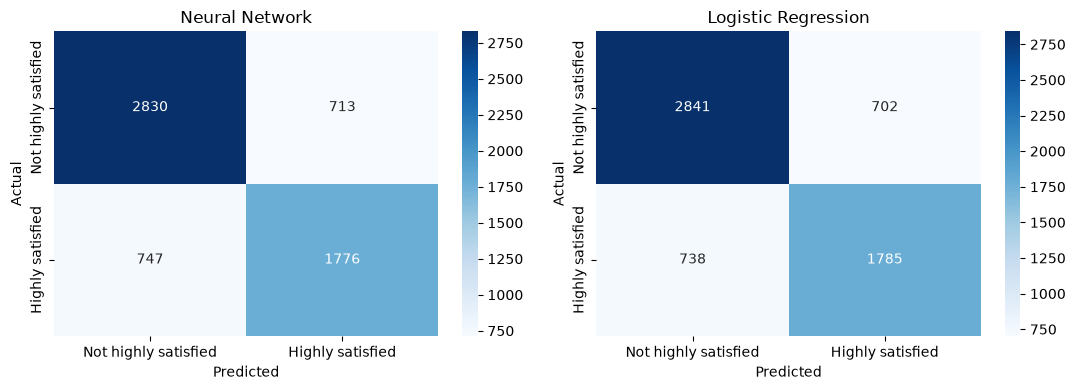

NN errors: 1460 | LR errors: 1440 | Both wrong: 1195

Errors by actual Q4 rating:


,Count,NN_Errors,NN_Error_Rate,LR_Errors,LR_Error_Rate
Q4_Numeric,,,,,
0.0,101,8,0.079,7,0.069
1.0,76,3,0.039,3,0.039
2.0,126,7,0.056,5,0.040
3.0,235,7,0.030,13,0.055
4.0,268,23,0.086,14,0.052
5.0,586,71,0.121,65,0.111
6.0,759,122,0.161,119,0.157
7.0,1392,472,0.339,476,0.342
8.0,1376,560,0.407,566,0.411


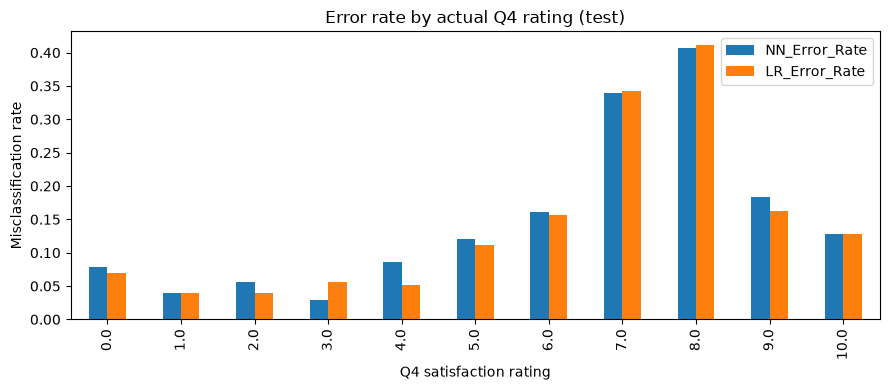

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, title, result in [
    (axes[0], "Neural Network", nn_test_metrics),
    (axes[1], "Logistic Regression", lr_test_metrics)
]:
    cm = confusion_matrix(y[test_idx], result["Predictions"], labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Not highly satisfied", "Highly satisfied"],
                yticklabels=["Not highly satisfied", "Highly satisfied"])
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

errors = pd.DataFrame({
    "Q4_Numeric": ajq.loc[test_idx, "Q4_Numeric"].to_numpy(),
    "Actual": y[test_idx],
    "NN_Predicted": nn_test_metrics["Predictions"],
    "LR_Predicted": lr_test_metrics["Predictions"],
    "NN_Probability": nn_test_metrics["Probabilities"],
    "LR_Probability": lr_test_metrics["Probabilities"]
})

errors["NN_Error"] = errors["Actual"] != errors["NN_Predicted"]
errors["LR_Error"] = errors["Actual"] != errors["LR_Predicted"]
errors["Both_Wrong"] = errors["NN_Error"] & errors["LR_Error"]

print("NN errors:", int(errors["NN_Error"].sum()),
      "| LR errors:", int(errors["LR_Error"].sum()),
      "| Both wrong:", int(errors["Both_Wrong"].sum()))
print("\nErrors by actual Q4 rating:")

by_rating = errors.groupby("Q4_Numeric").agg(
    Count=("Actual", "size"),
    NN_Errors=("NN_Error", "sum"),
    NN_Error_Rate=("NN_Error", "mean"),
    LR_Errors=("LR_Error", "sum"),
    LR_Error_Rate=("LR_Error", "mean")
)
display(by_rating.round(3))
errors.to_csv(OUTPUT_DIR / "nn_lr_test_error_analysis.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4))
by_rating[["NN_Error_Rate", "LR_Error_Rate"]].plot(kind="bar", ax=ax)
ax.set_title("Error rate by actual Q4 rating (test)")
ax.set_xlabel("Q4 satisfaction rating")
ax.set_ylabel("Misclassification rate")
plt.tight_layout()
plt.show()

## 12. Training curves and conclusions

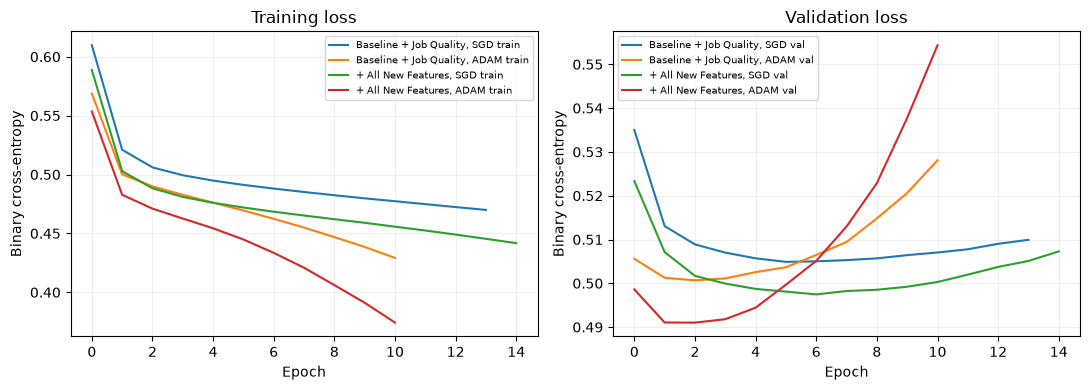

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for name in ("Baseline + Job Quality", "+ All New Features"):
    for optimizer in ("sgd", "adam"):
        hist = feature_histories[(name, optimizer)]
        axes[0].plot(hist["loss"], label=f"{name}, {optimizer.upper()} train")
        axes[1].plot(hist["val_loss"], label=f"{name}, {optimizer.upper()} val")

axes[0].set_title("Training loss")
axes[1].set_title("Validation loss")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Binary cross-entropy")
    ax.legend(fontsize=7)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()